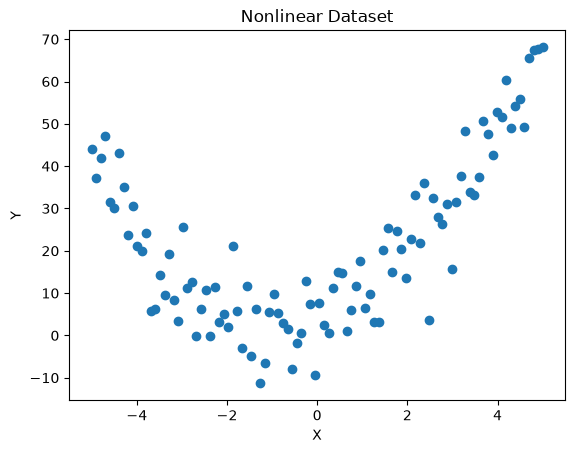

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

X = np.linspace(-5, 5, 100)

y = 2 * X**2 + 3 * X + 5 + np.random.normal(0, 8, 100)

plt.scatter(X, y)
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Nonlinear Dataset")
plt.show()

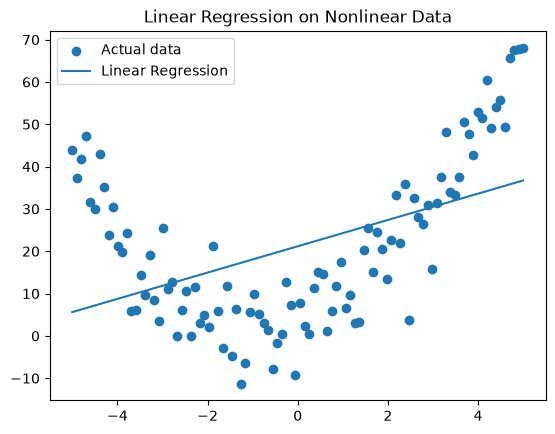

In [4]:
from sklearn.linear_model import LinearRegression

X_2d = X.reshape(-1, 1)

linear_model = LinearRegression()
linear_model.fit(X_2d, y)

linear_predictions = linear_model.predict(X_2d)

plt.scatter(X, y, label="Actual data")
plt.plot(X, linear_predictions, label="Linear Regression")
plt.legend()
plt.title("Linear Regression on Nonlinear Data")
plt.show()

Observe that the straight line cannot capture the quadratic relationship properly.

## Generate polynomial features
This is where PolynomialFeatures comes in.

For example, given \(x=3\), degree 2 generates:
\[
[1,x,x^2]=[1,3,9]
\]

With include_bias=False, it generates only:
\[
[x,x^2]=[3,9]
\]

### Transform the data

In [5]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(
    degree=2,
    include_bias=False
)

X_poly = poly.fit_transform(X_2d)

print("Original features:")
print(X_2d[:5])

print("\nPolynomial features:")
print(X_poly[:5])

Original features:
[[-5.       ]
 [-4.8989899]
 [-4.7979798]
 [-4.6969697]
 [-4.5959596]]

Polynomial features:
[[-5.         25.        ]
 [-4.8989899  24.00010203]
 [-4.7979798  23.02061014]
 [-4.6969697  22.06152433]
 [-4.5959596  21.12284461]]


Your single input feature has now become two features: \(x\) and \(x^2\).

In [13]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

poly_model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

poly_model.fit(X_2d, y)

poly_predictions = poly_model.predict(X_2d)

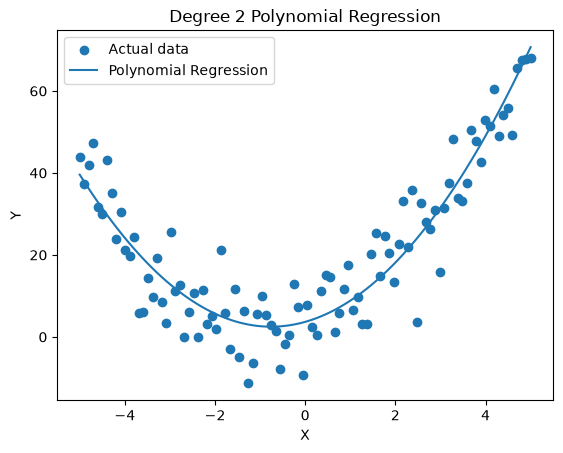

In [14]:
plt.scatter(X, y, label="Actual data")
plt.plot(X, poly_predictions, label="Polynomial Regression")

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Degree 2 Polynomial Regression")
plt.legend()
plt.show()

### Compare different polynomial degrees
A higher degree doesn't automatically mean a better model.

Let's compare degrees 1, 2, 5, and 15.

In [15]:
from sklearn.metrics import mean_squared_error

degrees = [1, 2, 5, 15]

results = []

for degree in degrees:
    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        LinearRegression()
    )

    model.fit(X_2d, y)

    predictions = model.predict(X_2d)

    mse = mean_squared_error(y, predictions)

    results.append({
        "Degree": degree,
        "MSE": mse
    })

results_df = pd.DataFrame(results)

print(results_df)

   Degree         MSE
0       1  296.935399
1       2   51.955116
2       5   48.826429
3      15   94.533436


In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_2d,
    y,
    test_size=0.2,
    random_state=42
)

In [17]:
results = []

for degree in [1, 2, 5, 15]:
    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        LinearRegression()
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    results.append({
        "Degree": degree,
        "Train_MSE": mean_squared_error(y_train, train_pred),
        "Test_MSE": mean_squared_error(y_test, test_pred)
    })

pd.DataFrame(results).round(2)

,Degree,Train_MSE,Test_MSE
0,1,308.63,255.90
1,2,55.06,39.66
2,5,51.02,41.54
3,15,87.32,150.90
